# FreeMol-Gen

設計與訓練完成的模型

重新載入與使用範例

In [ ]:
!pip install rdkit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.1/37.1 MB 37.7 MB/s eta 0:00:00


In [ ]:
import json
import os
import shutil
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import AllChem
from rdkit.Chem.Scaffolds import MurckoScaffold
from google.colab import drive


In [ ]:
# --- 1. 回建模型腳本 ---

@tf.keras.utils.register_keras_serializable()
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, use_causal_mask=False, **kwargs):
        super().__init__(**kwargs)
        self.embed_dim, self.num_heads, self.ff_dim, self.rate = embed_dim, num_heads, ff_dim, rate
        self.use_causal_mask = use_causal_mask
        self.att = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([tf.keras.layers.Dense(ff_dim, activation="relu"), tf.keras.layers.Dense(embed_dim)])
        self.layernorm1, self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6), tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1, self.dropout2 = tf.keras.layers.Dropout(rate), tf.keras.layers.Dropout(rate)
        self.supports_masking = True

    def call(self, inputs, training=None, mask=None):
        attn_output = self.att(inputs, inputs, attention_mask=mask, use_causal_mask=self.use_causal_mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.dropout2(self.ffn(out1), training=training)
        return self.layernorm2(out1 + ffn_output)

    def get_config(self):
        config = super().get_config()
        config.update({
            "embed_dim": self.embed_dim, "num_heads": self.num_heads,
            "ff_dim": self.ff_dim, "rate": self.rate, "use_causal_mask": self.use_causal_mask
        })
        return config

@tf.keras.utils.register_keras_serializable()
class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, max_len, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.max_len, self.vocab_size, self.embed_dim = max_len, vocab_size, embed_dim
        self.token_emb = tf.keras.layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = tf.keras.layers.Embedding(input_dim=max_len, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        return self.token_emb(x) + self.pos_emb(positions)

    def get_config(self):
        config = super().get_config()
        config.update({"max_len": self.max_len, "vocab_size": self.vocab_size, "embed_dim": self.embed_dim})
        return config



In [ ]:
# --- 2. 掛載與載入各項設定 ---
drive.mount('/content/drive')
pkg_path = '/content/drive/MyDrive/MD_and_CADD' # 這是掛載後的雲端資料夾路徑

with open(os.path.join(pkg_path, 'vocab_config.json'), 'r') as f:
    vocab_data = json.load(f)
char_to_id = vocab_data["char_to_id"]
id_to_char = {int(k): v for k, v in vocab_data["id_to_char"].items()}
vocab_size = len(char_to_id)
print(f"📖 [字典載入] 成功，詞彙表大小為 {vocab_size}")

# --- 3. 載入模型與權重 ---
# 因為我們有寫 get_config 和 register，load_model 會自動抓取參數
loaded_model = tf.keras.models.load_model(os.path.join(pkg_path, 'FreeMol-Gen_model.keras'))
loaded_model.summary()
print("[模型載入] 成功，已準備好進行藥物生成測試。")

Mounted at /content/drive
📖 [字典載入] 成功，詞彙表大小為 37


/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'token_and_position_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transformer_block', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'transformer_block_

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 127)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding    │ (None, 127, 128)       │        20,992 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ (None, 127, 128)       │       330,240 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 127, 37)        │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,040,177 (15.41 MB)

 Trainable params: 1,346,725 (5.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,693,452 (10.27 MB)

[模型載入] 成功，已準備好進行藥物生成測試。


In [ ]:
# --- 4. 推理生成器回建 (支援接續生成與機率紀錄) ---

def generate_drug_candidate(model, char_to_id, id_to_char, target_len=loaded_model.input_shape[1], temperature=1.0, prefix_smiles="", return_probs=False):
    """
    這是一個完整的 Transformer Decoder 推理流程。
    新增參數:
      - prefix_smiles (str): 預期接續的 SMILES 骨架字串，預設為空字串。
      - return_probs (bool): 是否回傳每一步的機率分佈與生成的字元，預設為 False。
    """
    # 1. 處理前綴字串：若無提供，預設只會放入 [BEGIN]
    tokens = ["[BEGIN]"] + list(prefix_smiles)
    pad_id = char_to_id["[PAD]"]
    # 轉換成 ID，若遇到字典中沒有的字元則預設為 PAD
    generated_ids = [char_to_id.get(c, pad_id) for c in tokens]

    # 用於儲存機率與字元的串列
    step_probabilities = []
    generated_tokens = []

    # 2. 開始自回歸生成 (從目前已有的長度開始往下生成)
    for i in range(target_len - len(generated_ids)):
        current_len = len(generated_ids)
        needed_pad = target_len - current_len

        # 準備維度為 (1, 101) 的輸入張量
        input_seq = np.array([generated_ids + [pad_id] * needed_pad])

        # 3. 模型預測
        predictions = model.predict(input_seq, verbose=0)

        # 4. 取得當前位置的 Logits 並進行溫度採樣
        logits = predictions[0, current_len - 1, :]

        # 避免 log(0)
        logits = np.log(logits + 1e-10) / temperature
        exp_logits = np.exp(logits)
        probs = exp_logits / np.sum(exp_logits)

        # --- 如果開啟紀錄，則儲存當前機率分布 ---
        if return_probs:
            step_probabilities.append(probs)

        # 5. 根據機率隨機選擇下一個原子
        next_token_id = np.random.choice(len(probs), p=probs)

        # --- 如果開啟紀錄，則儲存抽到的字元 ---
        if return_probs:
            generated_tokens.append(id_to_char[next_token_id])

        # 6. 如果抽到結束符號就停止
        if next_token_id == char_to_id["[END]"]:
            break

        generated_ids.append(next_token_id)

    # 7. 將 ID 序列轉回字串 (跳過開頭的 [BEGIN])
    smiles_str = "".join([id_to_char[idx] for idx in generated_ids[1:]])

    # 8. 根據開關決定回傳格式，確保舊代碼完全不受影響
    if return_probs:
        return smiles_str, step_probabilities, generated_tokens
    else:
        return smiles_str

 AI 藥物設計中 (使用溫度採樣)...
#01: Fc1cc(F)c(CC[NH2+]C2CC(c3cccnc3)C2)c(F)c1 (合法)
#02: Cc1cn[nH]c1C(=O)O[C@@H](C)c1ccccc1 (合法)
#03: CC(C)N(Cc1ccccc1)C(=O)NC1CC1 (合法)
#04: COc1cc(C)c(NC(=O)c2ccc(S(N)(=O)=O)c(N)c2)cc1OC (合法)
#05: CC[NH+](CCOC)Cc1ccc(NC(=O)[C@@H](C)Oc2ccccc2)cc1 (合法)
#06: Cc1ccsc1[C@@H]1C(C#N)=NN[C@H](c2ccc(Cl)c(Cl)c2)C(=O)N1 (合法)
#07: C[C@H]1CC[C@]2(C)CC[C@@H]3C(=NC4=CCN(c5ccccc5)CC4)C(=O)[C@@]3(C)[C@@]12C (合法)
#08: O=C(CC[NH+]1CCc2[nH]nc(-c3ccccc3)c2C1)N1CCc2ccccc21 (合法)
#09: CCN(C[C@H]1CCOC1)C(=O)N[C@H](CCS(C)(=O)=O)c1ccccc1 (合法)
#10: CNC(=O)c1ccc(NC(=O)c2cc[nH]n2)cc1Cl (合法)
----------------------------------------
  生成總數: 10
  合法分子數: 10
  成功率 (Validity): 100.0%

繪製 AI 設計出的合法藥物分子：


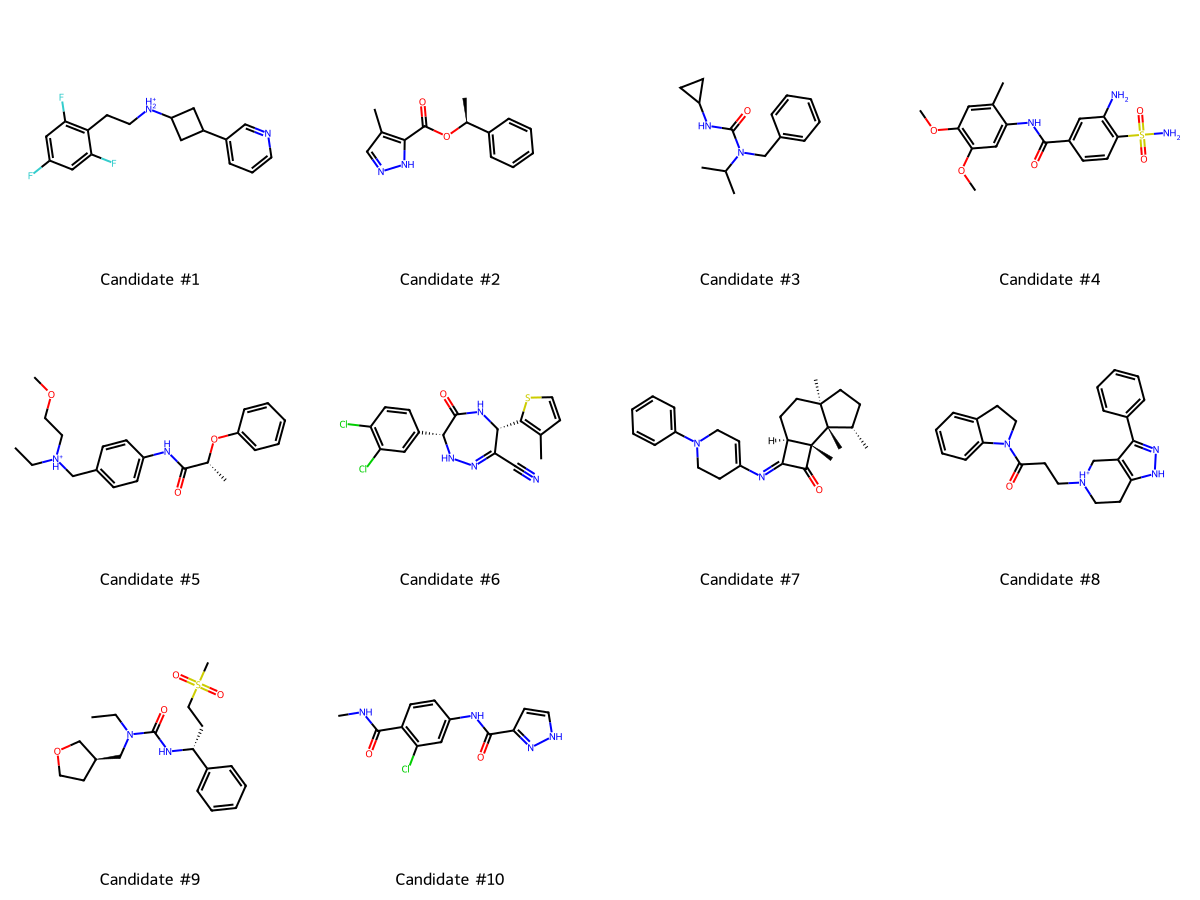

In [ ]:
# --- 5. 測試載入結果 ---

print(" AI 藥物設計中 (使用溫度採樣)...")

num_to_generate = 10  # 設定生成 10 個分子
temperature = 1.0 # 可以嘗試設置0.8 ~ 1.2之間，越大越有創造力
valid_mols = []
valid_indices = []
gen_smiles_list = []

for i in range(num_to_generate):
    # 建議溫度設定在 0.8 ~ 1.2 之間，1.0 是最平衡的
    smi = generate_drug_candidate(loaded_model, char_to_id, id_to_char, temperature=temperature)
    mol = Chem.MolFromSmiles(smi)

    gen_smiles_list.append(smi)

    # 判斷合法性
    status = "不合法"
    if mol:
        valid_mols.append(mol)
        valid_indices.append(i+1)
        status = "合法"

    print(f"#{i+1:02d}: {smi} ({status})")

# --- 6. 結果摘要與繪圖 ---

print("-" * 40)
print(f"  生成總數: {num_to_generate}")
print(f"  合法分子數: {len(valid_mols)}")
print(f"  成功率 (Validity): {len(valid_mols)/num_to_generate*100:.1f}%")

if valid_mols:
    print("\n繪製 AI 設計出的合法藥物分子：")
    img = Draw.MolsToGridImage(
        valid_mols,
        molsPerRow=4,
        subImgSize=(300, 300),
        legends=[f"Candidate #{idx}" for idx in valid_indices]
    )
    display(img)
else:
    print("\n提示：目前尚未生成合法分子，請檢查 Loss 是否已降至 1.0 以下。")

## 新分子驗證

我們希望AI自動生成的分子要能夠真實存在，並且不是單純只是從我們的資料集複製一份相同的出來。理想上，新分子應該是與原有分子相似但不相同，如果可以的話分子的核心骨架甚至也是全新的。因此我們將會測試以下幾種情況：

1. 有效性 (Validity)
2. 完全一致性檢查 (Exact Match)
3. 骨架新穎性 (Scaffold Novelty)
4. 重頭設計 (De Novo Design)
5. 化學指紋相似度 (Chemical Fingerprint Similarity)


In [ ]:
# 定義骨架生成函式
def get_scaffold_smiles(mol):
    # 1. 嘗試提取標準Murcko骨架
    scaf = MurckoScaffold.GetScaffoldForMol(mol)

    # 2. 如果沒有環則提取主鏈作為骨架
    if scaf.GetNumAtoms() == 0:
        # 建立分子樹
        dist_mat = rdmolops.GetDistanceMatrix(mol)
        # 找尋最長路徑的起點與終點
        start, end = np.unravel_index(dist_mat.argmax(), dist_mat.shape)
        path = rdmolops.GetShortestPath(mol, int(start), int(end))
        # 建立主鏈分子
        edit_mol = Chem.EditableMol(mol)
        for idx in sorted([a.GetIdx() for a in mol.GetAtoms()], reverse=True):
            if idx not in path:
                edit_mol.RemoveAtom(idx)
        scaf = edit_mol.GetMol()

    # 回傳Standard Scaffold SMILES
    return Chem.MolToSmiles(scaf)

In [ ]:
# 生成500個分子進行簡單驗證

num_to_generate = 500
temperature = 1.0
gen_smiles_list = []
valid_smiles_list = []
valid_scaffold_list = []


for i in range(num_to_generate):
    # 建議溫度設定在 0.8 ~ 1.2 之間，1.0 是最平衡的
    smi = generate_drug_candidate(loaded_model, char_to_id, id_to_char, temperature=temperature)
    mol = Chem.MolFromSmiles(smi)

    gen_smiles_list.append(smi)

    # 判斷合法性
    if mol:
        valid_mols.append(mol)
        valid_smiles_list.append(Chem.MolToSmiles(mol, isomericSmiles=True))
        valid_scaffold_list.append(get_scaffold_smiles(mol))



[03:49:01] Can't kekulize mol.  Unkekulized atoms: 24 25 26 27 28
[03:49:21] Can't kekulize mol.  Unkekulized atoms: 4 5 6 8 9 11 12
[03:50:10] Can't kekulize mol.  Unkekulized atoms: 1 2 3 11 12
[03:51:02] Can't kekulize mol.  Unkekulized atoms: 10 11 12 13 14
[03:51:47] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 6 7 8 23 25
[03:52:54] SMILES Parse Error: unclosed ring for input: 'Cc1ccc(C[C@@]2(C(=O)[O-])CCC[NH+]3CCCN(CCC[NH3+])C2)cc1'
[03:54:05] SMILES Parse Error: unclosed ring for input: 'Cc1ccc(N2C(=O)[C@@H]3C4c5ccccc5C(c4ccccc34)[C@H]3C2=O)cc1C'
[03:54:29] SMILES Parse Error: syntax error while parsing: CCCOc1ccc(S[C@@H]2CCCC[C@@]2([NH3NC(C)=O)C(=O)NC2CC2)cc1
[03:54:29] SMILES Parse Error: check for mistakes around position 34:
[03:54:29] @@H]2CCCC[C@@]2([NH3NC(C)=O)C(=O)NC2CC2)c
[03:54:29] ~~~~~~~~~~~~~~~~~~~~^
[03:54:29] SMILES Parse Error: extra open parentheses while parsing: CCCOc1ccc(S[C@@H]2CCCC[C@@]2([NH3NC(C)=O)C(=O)NC2CC2)cc1
[03:54:29] SMILES Parse Error: check f

In [ ]:
# 暫存一下生成的新藥物以免連線中斷
local_file_path = '/content/gen_smiles_500.txt'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/gen_smiles_500.txt'
with open(local_file_path, 'w') as f:
    for smi in gen_smiles_list:
        print(smi,file=f)
shutil.copy(local_file_path, output_file_path)

local_file_path = '/content/valid_smiles_500.txt'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/valid_smiles_500.txt'
with open(local_file_path, 'w') as f:
    for smi in valid_smiles_list:
        print(smi,file=f)
shutil.copy(local_file_path, output_file_path)

local_file_path = '/content/valid_scaffold_500.txt'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/valid_scaffold_500.txt'
with open(local_file_path, 'w') as f:
    for smi in valid_scaffold_list:
        print(smi,file=f)
shutil.copy(local_file_path, output_file_path)

'/content/drive/MyDrive/MD_and_CADD/valid_scaffold_500.txt'

In [ ]:
# 讀取之前生成的新藥物
input_file_path = '/content/drive/MyDrive/MD_and_CADD/gen_smiles_500.txt'
with open(input_file_path, 'r') as f:
    gen_smiles_list = [line.strip() for line in f]

input_file_path = '/content/drive/MyDrive/MD_and_CADD/valid_smiles_500.txt'
with open(input_file_path, 'r') as f:
    valid_smiles_list = [line.strip() for line in f]

input_file_path = '/content/drive/MyDrive/MD_and_CADD/valid_scaffold_500.txt'
with open(input_file_path, 'r') as f:
    valid_scaffold_list = [line.strip() for line in f]


In [ ]:
# 從預處理資料中讀取SMILES和Scaffold
df = pd.read_csv('/content/drive/MyDrive/MD_and_CADD/smiles_and_properties.csv')
all_smiles = df['SMILES']
all_scaffold = df['Standard_Scaffold']

In [ ]:
# 利用 Python 的 set 可以進行O(1)複雜度的比對
# 1. 訓練集轉換成set資料型態
train_smiles_set = set(all_smiles)
train_scaffold_set = set(all_scaffold)

# 2. 通過驗證的新分子與新骨架轉換成set資料型態
valid_smiles_set = set(valid_smiles_list)
valid_scaffold_set = set(valid_scaffold_list)

# 3. 計算指標
print("--- 指標報告 ---")

# 指標A: 生成分子的有效性
# 定義為總生成分子中有多少分子是合法有效的
print(f"生成分子有效率: {len(valid_smiles_list) / len(gen_smiles_list) * 100:.2f} %")

# 指標B: 生成分子的重複率
# 定義為生成的合法分子中有多少比率是重複的
print(f"生成分子重複率: {(1 - len(valid_smiles_set) / len(valid_smiles_list)) * 100:.2f}%")

# 指標C: 生成分子的新穎性
# 定義為所有生成的未重複合法分子中未存在於訓練集的比例
print(f"生成分子新穎率: {len(valid_smiles_set - train_smiles_set) / len(valid_smiles_set) * 100:.2f}%")

# 指標D: 生成分子的骨架新穎性
# 定義為所有生成的未重複骨架中未存在於訓練集骨架的比例
print(f"生成骨架新穎率: {len(valid_scaffold_set - train_scaffold_set) / len(valid_scaffold_set) * 100:.2f}%")

# 指標E: 重頭設計率
# 定義為所有生成的不重複分子中有多少比例是骨架跟分子本身都是全新的
new_scaffold_set = valid_scaffold_set - train_scaffold_set
mols_with_new_scaffold_count = sum(1 for scaf in valid_scaffold_list if scaf in new_scaffold_set)
print(f"重頭設計率： {mols_with_new_scaffold_count / len(valid_smiles_set) * 100:.2f}%")





--- 指標報告 ---
生成分子有效率: 91.40 %
生成分子重複率: 0.00%
生成分子新穎率: 100.00%
生成骨架新穎率: 65.97%
重頭設計率： 61.93%


## 指標報告解析
分子有效率 - 越高代表模型已掌握SMILES大部分的語法規則  
分子重複率 - 越低代表模型的預測分布非常廣，沒有陷入只會重複生成特定幾種分子  
分子新穎率 - 越高代表模型是真實在建立全新分子，而不是抄襲訓練集內的已知分子  
骨架新穎率 - 越高代表模型並沒有高度依賴已知骨架做為基礎在建立新分子  
重新設計率 - 越高代表模型已開始嘗試探索全新的未知分子




**但，能達這件事情是模型本身的架構?還是Temperature超參數的影響?**




In [ ]:
# 化學指紋相似度
# 初始化產生器
rdk_gen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)
train_smiles_set_fps = [rdk_gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in train_smiles_set]

# 計算生成小分子的統計數據
valid_smiles_max_sims = []
for s_valid in valid_smiles_set:
    mol = Chem.MolFromSmiles(s_valid)
    query_fp = rdk_gen.GetFingerprint(mol)
    sims = DataStructs.BulkTanimotoSimilarity(query_fp, train_smiles_set_fps)
    valid_smiles_max_sims.append(max(sims))



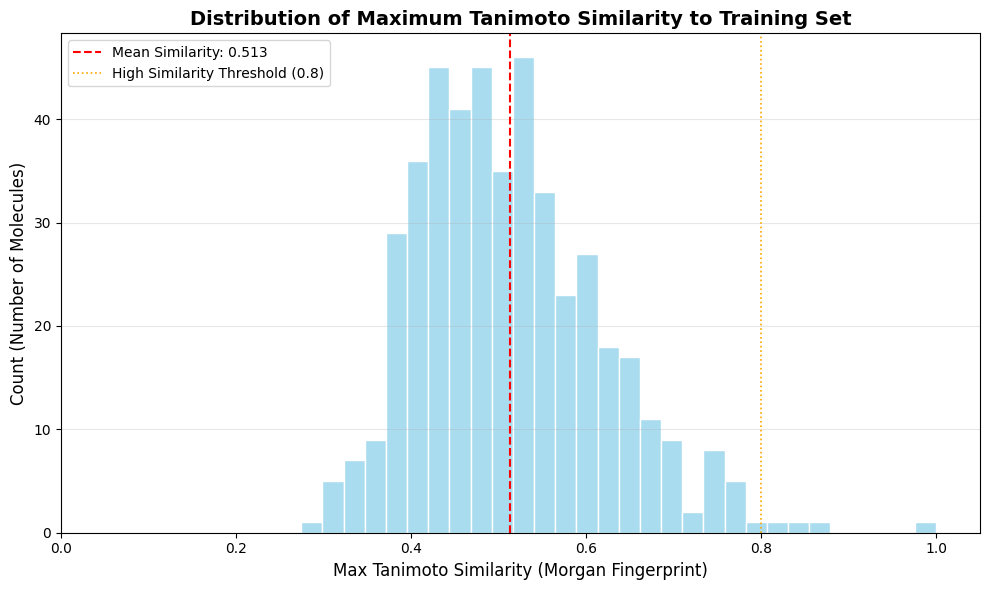

In [ ]:
# 與訓練集之間的相似度分布
def plot_similarity_distribution(max_sims):
    plt.figure(figsize=(10, 6))

    # 1. 繪製直方圖與密度曲線
    sns.histplot(max_sims, bins=30, kde=False, color='skyblue', edgecolor='white', alpha=0.7)

    # 2. 設定 X 軸範圍 (Tanimoto 相似度必在 0~1 之間)
    plt.xlim(0, 1.05)

    # 3. 加上統計參考線 (平均值)
    mean_sim = np.mean(max_sims)
    plt.axvline(mean_sim, color='red', linestyle='--', linewidth=1.5,
                label=f'Mean Similarity: {mean_sim:.3f}')

    # 4. 加上藥物設計的常見分界點 (例如 0.8 以上視為高度雷同)
    plt.axvline(0.8, color='orange', linestyle=':', linewidth=1.2, label='High Similarity Threshold (0.8)')

    # 5. 圖表標籤與標題
    plt.title('Distribution of Maximum Tanimoto Similarity to Training Set', fontsize=14, fontweight='bold')
    plt.xlabel('Max Tanimoto Similarity (Morgan Fingerprint)', fontsize=12)
    plt.ylabel('Count (Number of Molecules)', fontsize=12)

    # 6. 美化
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()

    plt.show()

plot_similarity_distribution(valid_smiles_max_sims)

## 接續生成


In [ ]:
def plot_full_heatmap_with_annotations(step_probs, generated_tokens, id_to_char, threshold=0.1):
    """
    繪製完整的機率熱力圖，並針對高機率的預測加上數值標註。

    參數:
      - step_probs: 每步生成的機率分佈列表
      - generated_tokens: 實際抽出的字元列表
      - id_to_char: ID 對應字元的字典
      - threshold: 顯示數字的機率門檻 (預設 0.1，即大於 10% 才顯示數字)
    """
    if not step_probs:
        print("提示：沒有生成任何新字元，無法繪製熱力圖。")
        return

    # 1. 將機率資料轉為 NumPy 矩陣，形狀為 (vocab_size, 生成步數)
    probs_matrix = np.array(step_probs).T

    # 2. 取得完整的 Y 軸標籤 (字典裡的所有字元)
    vocab_size = probs_matrix.shape[0]
    y_labels = [id_to_char[idx] for idx in range(vocab_size)]
    x_labels = generated_tokens

    # 3. 準備「標註矩陣 (Annotation Matrix)」
    # 只有當機率 >= threshold 時才放入數字字串，否則留空
    annot_matrix = np.empty_like(probs_matrix, dtype=object)
    for i in range(probs_matrix.shape[0]):
        for j in range(probs_matrix.shape[1]):
            if probs_matrix[i, j] >= threshold:
                annot_matrix[i, j] = f"{probs_matrix[i, j]:.2f}" # 保留小數點後兩位
            else:
                annot_matrix[i, j] = ""

    # 4. 動態設定畫布大小 (因為 Y 軸變長了，高度需要拉高)
    plt.figure(figsize=(max(10, len(x_labels) * 0.5), max(8, vocab_size * 0.25)))

    # 5. 繪製熱力圖
    sns.heatmap(probs_matrix,
                annot=annot_matrix,   # 傳入我們自訂的標註矩陣
                fmt="",               # 必須設為空字串，讓 seaborn 乖乖吃我們的字串矩陣
                cmap="viridis",
                xticklabels=x_labels,
                yticklabels=y_labels,
                cbar_kws={'label': 'Probability'},
                linewidths=0.5,       # 加上細細的格線，讓標註的格子更像一個表格
                linecolor='black')

    plt.title(f"Full Vocabulary Probability Heatmap (Annotated > {threshold})", fontsize=14, fontweight='bold')
    plt.xlabel("Generated Tokens (Step-by-Step)", fontsize=12)
    plt.ylabel("Vocabulary (All Characters)", fontsize=12)
    plt.yticks(rotation=0)

    # 小技巧：把 X 軸的刻度移到上方，這樣對照生成的字元時脖子比較不酸
    plt.tick_params(axis='x', bottom=False, top=True, labelbottom=False, labeltop=True)

    plt.tight_layout()
    plt.show()

給定的前綴骨架: 
最終生成分子: CCS[C@H]1C[C@@H]([NH3+])[C@H](C)Oc2ccc(F)c(Cl)c21
✅ 測試結果: 這是合法的化學分子！


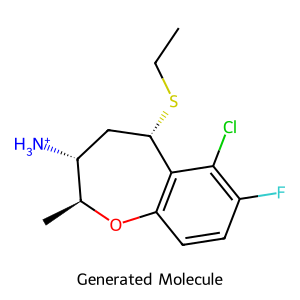


繪製生成機率熱力圖...


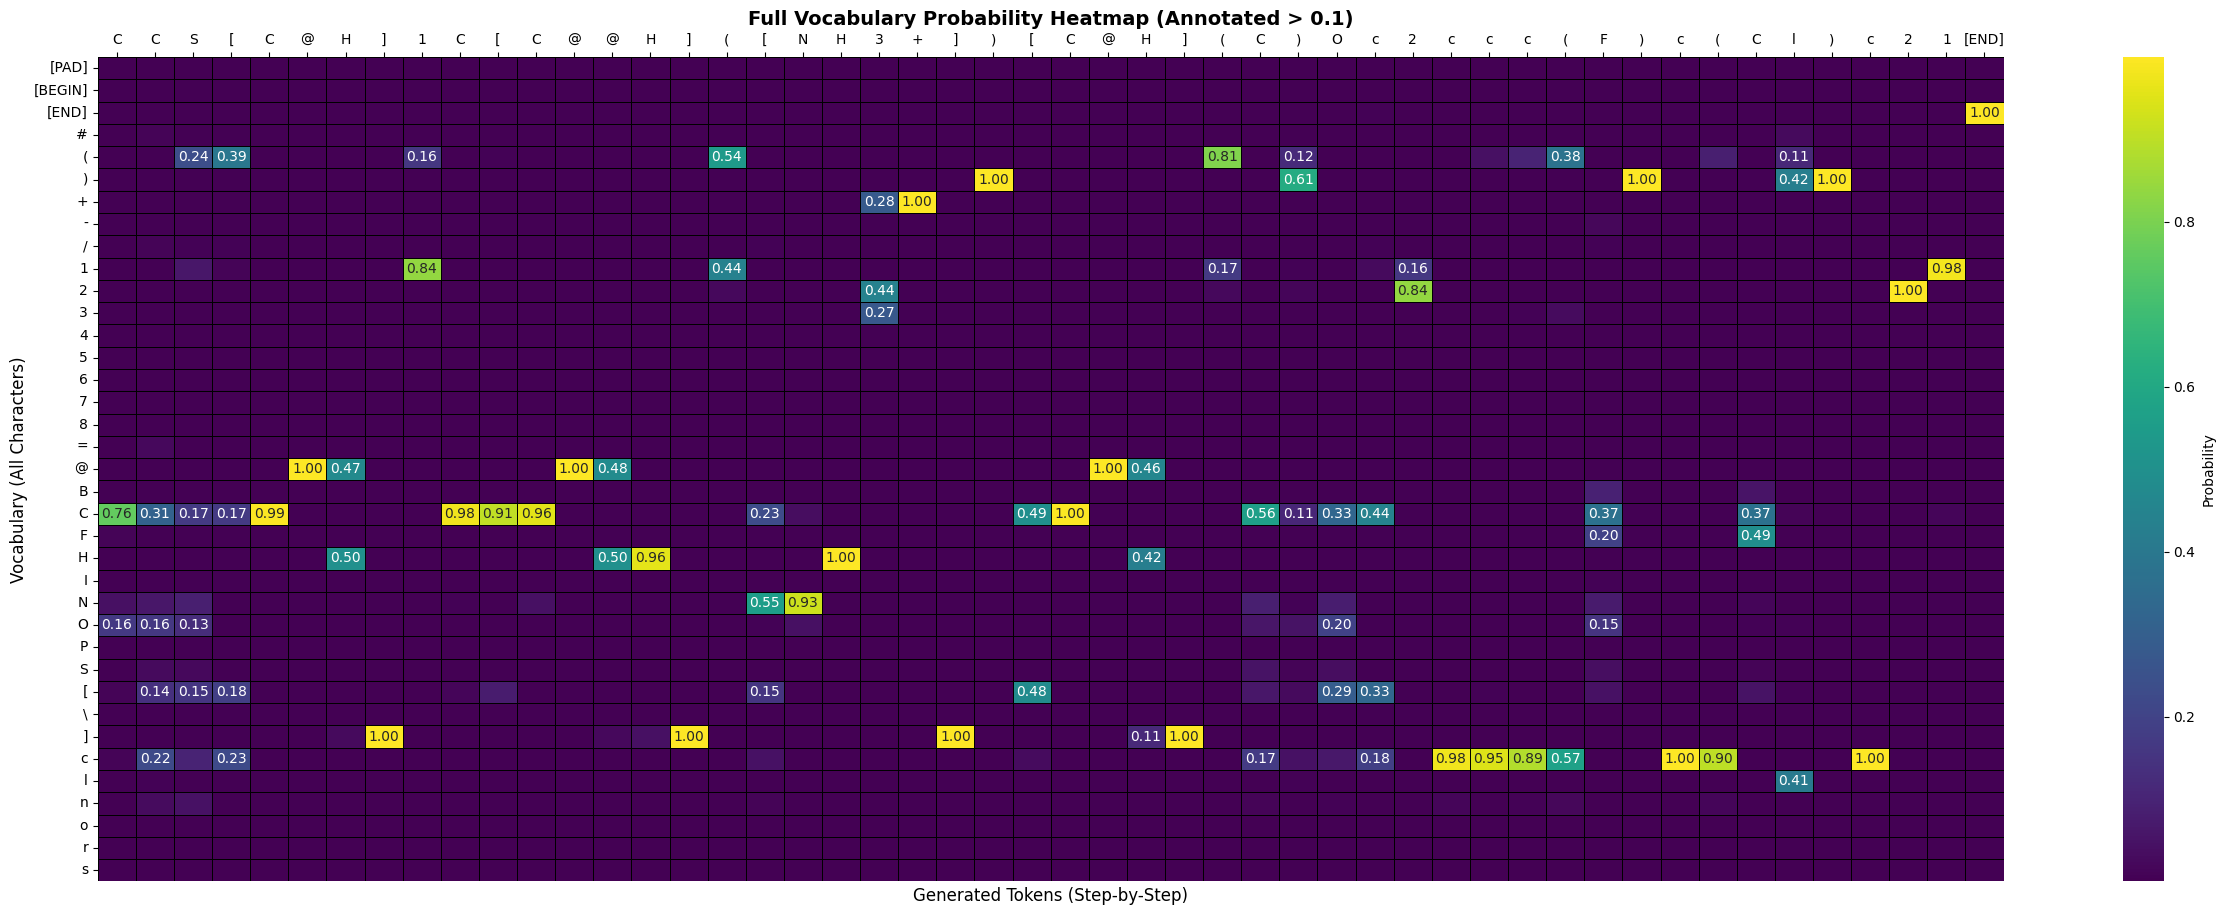

In [ ]:
# 1. 設定你想要接續的開頭骨架
#my_prefix = "c1ccccc1C(=O)"
my_prefix = ""
print(f"給定的前綴骨架: {my_prefix}")

# 2. 呼叫更新後的生成器
smi_result, probs_history, new_tokens = generate_drug_candidate(
    loaded_model,
    char_to_id,
    id_to_char,
    temperature=1.2,
    prefix_smiles=my_prefix,
    return_probs=True
)

print(f"最終生成分子: {smi_result}")

# 3. 進行合法性測試與結構視覺化
mol = Chem.MolFromSmiles(smi_result)

if mol:
    print("✅ 測試結果: 這是合法的化學分子！")
    # 順手把分子畫出來，方便對照
    img = Draw.MolToImage(mol, size=(300, 300), legend="Generated Molecule")
    display(img)
else:
    print("❌ 測試結果: 生成失敗，這不是合法的分子 (SMILES 語法錯誤或化學價數不合理)。")

# 4. 呼叫繪圖函式，繪製熱力圖
print("\n繪製生成機率熱力圖...")
plot_full_heatmap_with_annotations(probs_history, new_tokens, id_to_char, threshold=0.1)

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

def interactive_grid_temperature_viewer(step_probs, generated_tokens, id_to_char, prefix_smiles="", original_temp=1.0):
    """
    動態網格排版：上方顯示 0.0 與 Target，下方橫向顯示其他過渡溫度
    (修正 X 軸標籤對齊與大小)
    """
    if not step_probs:
        print("提示：沒有生成任何新字元。")
        return

    vocab_size = len(id_to_char)
    all_chars = [id_to_char[i] for i in range(vocab_size)]
    max_step = len(generated_tokens) - 1

    # 定義要顯示的溫度
    base_temps = [0.0, 0.2, 0.5, 0.8]
    display_temps = list(set([t for t in base_temps if t < original_temp] + [original_temp, 0.0]))
    display_temps.sort()

    temp_0 = 0.0
    temp_target = original_temp
    other_temps = [t for t in display_temps if t not in (temp_0, temp_target)]

    # UI 控制元件
    step_slider = widgets.IntSlider(value=0, min=0, max=max_step, step=1, description='Step:', continuous_update=False)
    prev_btn = widgets.Button(description='◀ 上一步', button_style='info', layout=widgets.Layout(width='auto'))
    next_btn = widgets.Button(description='下一步 ▶', button_style='info', layout=widgets.Layout(width='auto'))

    html_output = widgets.HTML()
    plot_output = widgets.Output()

    def on_prev_click(b):
        if step_slider.value > 0:
            step_slider.value -= 1

    def on_next_click(b):
        if step_slider.value < max_step:
            step_slider.value += 1

    prev_btn.on_click(on_prev_click)
    next_btn.on_click(on_next_click)

    # 共用的繪製單一圖表函式
    def draw_bar(ax, t, raw_logits, current_probs, current_char, is_target=False, is_zero=False):
        if t == original_temp:
            probs_to_plot = current_probs
        else:
            calc_t = 0.01 if t == 0.0 else t
            logits_t = raw_logits / calc_t
            exp_t = np.exp(logits_t - np.max(logits_t))
            probs_to_plot = exp_t / np.sum(exp_t)

        if is_target:
            base_color = 'lightgreen'
            title = f"Temp = {t} (Target)"
        elif is_zero:
            base_color = 'lightskyblue'
            title = f"Temp = 0.0 (Greedy)"
        else:
            base_color = 'khaki' if t >= 0.5 else 'powderblue'
            title = f"Temp = {t}"

        bars = ax.bar(all_chars, probs_to_plot, color=base_color, edgecolor='black')

        ax.set_title(title, fontsize=11, fontweight='bold', pad=5)
        ax.set_ylim(0, 1.1)
        ax.grid(axis='y', alpha=0.3)
        ax.tick_params(axis='y', labelsize=8)

        for bar, char in zip(bars, all_chars):
            if char == current_char:
                bar.set_color('coral')
                bar.set_edgecolor('black')
                bar.set_linewidth(1.2)

        for j, p in enumerate(probs_to_plot):
            if p > 0.05:
                ax.text(j, p + 0.03, f"{p:.2f}", ha='center', fontsize=8)

        # 【重點修正】: 縮小字體 (fontsize=7)，並加上 rotation_mode='anchor' 確保對齊
        ax.set_xticks(range(vocab_size))
        ax.set_xticklabels(all_chars, rotation=60, ha='right', rotation_mode='anchor', fontsize=7)

    def update_view(change):
        step_idx = change['new'] if isinstance(change, dict) else change

        past_str = prefix_smiles + "".join(generated_tokens[:step_idx])
        current_char = generated_tokens[step_idx]

        html_content = f"""
        <div style="font-size: 16px; margin: 5px 0; font-family: monospace; padding: 8px; background-color: #f0f0f0; border-radius: 5px;">
            <strong>Step {step_idx + 1}: </strong>
            <span style="color: black;">{past_str}</span><span style="color: red; font-weight: bold; text-decoration: underline;">{current_char}</span>
        </div>
        """
        html_output.value = html_content

        with plot_output:
            clear_output(wait=True)

            fig = plt.figure(figsize=(14, 6.5))
            num_others = max(1, len(other_temps))
            cols = 2 * num_others
            gs = gridspec.GridSpec(2, cols, figure=fig) # 交給 tight_layout 處理間距

            current_probs = step_probs[step_idx]
            raw_logits = np.log(current_probs + 1e-10) * original_temp

            ax_0 = fig.add_subplot(gs[0, :num_others])
            ax_target = fig.add_subplot(gs[0, num_others:])

            draw_bar(ax_0, temp_0, raw_logits, current_probs, current_char, is_zero=True)
            draw_bar(ax_target, temp_target, raw_logits, current_probs, current_char, is_target=True)

            for i, t in enumerate(other_temps):
                ax_other = fig.add_subplot(gs[1, i*2 : (i+1)*2])
                draw_bar(ax_other, t, raw_logits, current_probs, current_char)

            # 自動計算並完美貼合所有子圖間距與邊界，避免標籤被切掉
            fig.tight_layout()
            plt.show()

    step_slider.observe(update_view, names='value')

    controls = widgets.HBox([prev_btn, step_slider, next_btn], layout=widgets.Layout(align_items='center'))
    ui = widgets.VBox([controls, html_output, plot_output])

    display(ui)
    update_view(0)

In [ ]:
# 請確保函式名稱有 "multi"
interactive_grid_temperature_viewer(probs_history, new_tokens, id_to_char, prefix_smiles=my_prefix, original_temp=1.2)

##